# Force Density Method

A runnable walk through K. Linkwitz, *Force density method: design of a timber shell*, Chapter 6 of
*Shell Structures for Architecture* (Routledge 2014), in the order of the book's sections, with every equation
computed on the chapter's own example: one free node $P_0$ held by four bars $a, b, c, d$ to the anchors of
exercise 2 (p. 68),

$$
P_1 (0, 0, 0), \quad P_2 (5, 0, 3), \quad P_3 (0, 7, 3), \quad P_4 (7, 5, 0), \qquad q = 1 \text{ kN/m in every bar}, \qquad p_z = -5 \text{ kN}.
$$

**Run the cells in order.** Each section first states the book's equation, then the same equation with the
numbers, then the code and its output. The companion in Schek's notation (9-node net) is [compas_fd.ipynb](compas_fd.ipynb).

| Linkwitz | Schek / compas_fd | meaning |
|---|---|---|
| $\mathbf C = [\mathbf C _ N \ \mathbf C _ F]$ | $C_s = [C \mid C_f]$ | branch-node matrix, free and fixed columns |
| $\mathbf x _ N, \mathbf x _ F$ | $\mathbf x, \mathbf x _ f$ | free and fixed coordinates |
| $\mathbf f$, $\mathbf q = \mathbf L^{-1} \mathbf f$ | $\mathbf s$, $\mathbf q = \mathbf s / \mathbf l$ | bar forces and force densities |
| $\mathbf D _ N$, $\mathbf D _ F$ | $D$, $D_f$ | the two tables of force densities that make up the system of equations (one row per free node): $\mathbf D _ N$ free–free (diagonal = $q$'s at the node, off-diagonal = $-q$ of the bar between two free nodes), $\mathbf D _ F$ free–anchor ($-q$ of the bar to that anchor) |
| $\mathbf D _ N \mathbf x _ N = \mathbf p - \mathbf D _ F \mathbf x _ F$ (6.31) | $D \mathbf x = \mathbf p _ x - D_f \mathbf x _ f$ | the linear system |


## § 6.2.1 A single node in equilibrium

Fig. 6.4 of the book: node $P_0$ connected to four fixed points $P_1 \ldots P_4$ by bars $a, b, c, d$, with a load $p_z$.
The numbers are those of exercise 2 (p. 68). The load vector is $\mathbf p = (0, 0, -5)$ kN: gravity acts in $-z$.
$P_0$ is unknown; the method will find $P_0 = (3, 3, 0.25)$.

![Fig. 6.4 — the single node P0 with the four bars a, b, c, d to P1 … P4 and the load p_z](https://pub-c082064d3c234b25bcb6abd4240e637c.r2.dev/force-density-linkwitz/notes/images/fig6-4-node.jpg)

*Figure 6.4 of the book: a single node with four forces and a load.*

*Cell A.1 — 6.2.1 A single node in equilibrium — the data of the exercise (p. 68)*


In [1]:
import numpy as np

np.set_printoptions(precision=4, suppress=True, linewidth=110)

# Fixed points P1..P4 of the chapter's exercises (p. 68), one row per point, columns x y z (m)
P_fixed = np.array([[0.0, 0.0, 0.0],    # P1
                    [5.0, 0.0, 3.0],    # P2
                    [0.0, 7.0, 3.0],    # P3
                    [7.0, 5.0, 0.0]])   # P4
p = np.array([0.0, 0.0, -5.0])          # load on P0 (kN): 5 kN gravity acts in -z
q = np.array([1.0, 1.0, 1.0, 1.0])      # force densities of bars a b c d (kN/m)
bars = ["a", "b", "c", "d"]

print("fixed points (4x3):\n", P_fixed)
print("load p =", p, "kN   force densities q =", q, "kN/m")


fixed points (4x3):
 [[0. 0. 0.]
 [5. 0. 3.]
 [0. 7. 3.]
 [7. 5. 0.]]
load p = [ 0.  0. -5.] kN   force densities q = [1. 1. 1. 1.] kN/m


## § 6.2.2 Translation to equations

**Equation (6.2)** — every bar is as long as the distance between its end points, so the four lengths are a function of the unknown $P_0$:

$$
l_i = \sqrt{(x_k - x_0)^2 + (y_k - y_0)^2 + (z_k - z_0)^2}, \qquad k = 1, 2, 3, 4
$$

At a guess $P_0 = (3, 3, 1)$: $l_a = \sqrt{9 + 9 + 1} = 4.359$ m.

*Cell B.1 — 6.2.2 Translation to equations — bar lengths, equation (6.2)*


In [2]:
def lengths(P0):
    """(6.2): l_k = sqrt((x_k-x0)^2 + (y_k-y0)^2 + (z_k-z0)^2) for the four bars, as one array."""
    return np.linalg.norm(P_fixed - P0, axis=1)


P0_guess = np.array([3.0, 3.0, 1.0])
print("guess P0 =", P0_guess, " -> lengths l =", lengths(P0_guess))


guess P0 = [3. 3. 1.]  -> lengths l = [4.3589 4.1231 5.3852 4.5826]


**Equations (6.4)–(6.6)** — the pull $F_i$ of a bar acts along the bar; its $x$-part is $F_i \cos \alpha_i$ with the direction cosine
"coordinate difference ÷ distance in space". Equilibrium of the four parts and the load, in each direction:

$$
\frac{x_1 - x_0}{l_a} F_a + \frac{x_2 - x_0}{l_b} F_b + \frac{x_3 - x_0}{l_c} F_c + \frac{x_4 - x_0}{l_d} F_d + p_x = 0
$$

The code evaluates the left side as a residual: zero means equilibrium. At the guess with $F = 1$ kN (exercise 1) it is $-4.59$ kN in $z$: four pulls of 1 kN lift only $0.41$ kN against 5 kN.

*Cell B.2 — 6.2.2 Translation to equations — direction cosines and equilibrium, (6.4)–(6.6)*


In [3]:
def residual(P0, F):
    """(6.6) in x, y and z at once: sum_k (P_k - P0)/l_k * F_k + p.  Zero when P0 is in equilibrium."""
    l = lengths(P0)
    cosines = (P_fixed - P0) / l[:, None]          # (6.4): direction cosines, one row per bar
    return (cosines * F[:, None]).sum(axis=0) + p


F_guess = np.array([1.0, 1.0, 1.0, 1.0])            # kN, as in exercise 1
print("direction cosines at the guess:\n", (P_fixed - P0_guess) / lengths(P0_guess)[:, None])
print("residual (6.6) at the guess with F = 1 kN:", residual(P0_guess, F_guess), " <- not zero, not in equilibrium")


direction cosines at the guess:
 [[-0.6882 -0.6882 -0.2294]
 [ 0.4851 -0.7276  0.4851]
 [-0.5571  0.7428  0.3714]
 [ 0.8729  0.4364 -0.2182]]
residual (6.6) at the guess with F = 1 kN: [ 0.1126 -0.2366 -4.5912]  <- not zero, not in equilibrium


## § 6.2.3 Force densities

$x_0$ sits inside the square roots: (6.6) is nonlinear. **Equation (6.10)** defines the force density $q_i := F_i / l_i$; then (6.6) becomes **(6.11)**, linear in $x_0$, and **(6.13)** solves it:

$$
(x_1 - x_0) q_a + \ldots + (x_4 - x_0) q_d + p_x = 0
\qquad \Longrightarrow \qquad
x_0 = \frac{p_x + x_1 q_a + x_2 q_b + x_3 q_c + x_4 q_d}{q_a + q_b + q_c + q_d}
$$

$$
x_0 = \frac{0 + 0 + 5 + 0 + 7}{4} = 3, \qquad y_0 = \frac{0 + 0 + 0 + 7 + 5}{4} = 3, \qquad z_0 = \frac{-5 + 0 + 3 + 3 + 0}{4} = 0.25
$$

Afterwards the pulls follow from the shape, $F_k = q_k l_k$ (6.33), and the residual of (6.6) is exactly zero.

*Cell B.3 — 6.2.3 Force densities — the linear solution, (6.10)–(6.13)*


In [4]:
def solve_single_node(q):
    """(6.13): P0 = (p + sum_k q_k P_k) / sum_k q_k, one line per coordinate."""
    return (p + (q[:, None] * P_fixed).sum(axis=0)) / q.sum()


P0 = solve_single_node(q)
l = lengths(P0)
F = q * l                                           # (6.33): the forces follow from the shape, F_k = q_k l_k
print("numerator  p + sum q_k P_k =", p + (q[:, None] * P_fixed).sum(axis=0))
print("denominator sum q_k        =", q.sum())
print("P0 (6.13)                  =", P0)
for k in range(4):
    print(f"  bar {bars[k]}: l = {l[k]:.4f} m, F = q l = {F[k]:.4f} kN")
print("residual (6.6) at P0       =", residual(P0, F), " <- equilibrium")


numerator  p + sum q_k P_k = [12. 12.  1.]
denominator sum q_k        = 4.0
P0 (6.13)                  = [3.   3.   0.25]
  bar a: l = 4.2500 m, F = q l = 4.2500 kN
  bar b: l = 4.5346 m, F = q l = 4.5346 kN
  bar c: l = 5.7064 m, F = q l = 5.7064 kN
  bar d: l = 4.4791 m, F = q l = 4.4791 kN
residual (6.6) at P0       = [0. 0. 0.]  <- equilibrium


Doubling $q$ in bars $b$ and $d$ moves the node towards $P_2$ and $P_4$; the formula is unchanged, only the weights:

$$
x_0 = \frac{0 + 0 \cdot 1 + 5 \cdot 2 + 0 \cdot 1 + 7 \cdot 2}{1 + 2 + 1 + 2} = 4
$$

*Cell B.4 — 6.2.3 Force densities — changing q (exercise 2, second part)*


In [5]:
q2 = np.array([1.0, 2.0, 1.0, 2.0])                 # stiffer bars b and d
P0b = solve_single_node(q2)
print("q =", q2, " -> P0 =", P0b)
print("  P0 moved from", P0, "towards the midpoint of P2 and P4", (P_fixed[1] + P_fixed[3]) / 2)
print("  forces F = q l =", q2 * lengths(P0b), "kN;  residual =", residual(P0b, q2 * lengths(P0b)))


q = [1. 2. 1. 2.]  -> P0 = [4.     2.8333 0.6667]
  P0 moved from [3.   3.   0.25] towards the midpoint of P2 and P4 [6.  2.5 1.5]
  forces F = q l = [4.9469 7.6085 6.2294 7.5203] kN;  residual = [ 0. -0.  0.]


If the *forces* are prescribed instead (exercise 1), $q_k = F_k / l_k$ changes with the geometry and (6.13) must be iterated.
With $F = 2$ kN it converges; with $F = 1$ kN it never does — four forces of 1 kN pull upwards with at most 4 kN together,
so no position balances 5 kN. That is the observation the exercise asks for, and the reason the chapter prescribes $q$.

*Cell B.5 — 6.2.3 Force densities — why prescribed forces are nonlinear (exercise 1)*


In [6]:
def solve_with_forces(F, P0, steps=300):
    """Fixed-point iteration: with the current P0 compute l, turn the given forces into q = F/l (6.10),
    solve the linear (6.13), repeat until P0 stops moving.  Returns P0 and the number of steps."""
    for it in range(steps):
        P0_new = solve_single_node(F / lengths(P0))
        if np.linalg.norm(P0_new - P0) < 1e-12:
            return P0_new, it + 1
        P0 = P0_new
    return P0, steps


P0c, its = solve_with_forces(2.0 * np.ones(4), P0_guess)
print(f"F = 2 kN in every bar: converged in {its} steps to P0 =", P0c, " q = F/l =", 2.0 / lengths(P0c))
P0d, its = solve_with_forces(1.0 * np.ones(4), P0_guess, steps=100)
print(f"F = 1 kN in every bar: after {its} steps P0 =", P0d, " residual =", residual(P0d, np.ones(4)))
print("  four forces of 1 kN pull up with at most 4 kN together: a 5 kN load cannot be balanced")


F = 2 kN in every bar: converged in 35 steps to P0 = [ 3.1102  2.7427 -2.3093]  q = F/l = [0.4214 0.3191 0.2673 0.3956]
F = 1 kN in every bar: after 100 steps P0 = [ 3.0000e+00  3.0000e+00 -3.6304e+10]  residual = [-0.  0. -1.]
  four forces of 1 kN pull up with at most 4 kN together: a 5 kN load cannot be balanced


## § 6.4 Notation

A vector is a one-column matrix; $\mathbf A = \mathrm{diag}(\mathbf a)$ puts it on a diagonal. The only purpose of the diagonal
matrices in this chapter is to write an element-by-element product of two vectors as a matrix product:

$$
\mathbf U \mathbf q = \mathbf Q \mathbf u = (u_k q_k)
$$

*Cell C.1 — 6.4 Notation — vectors and diagonal matrices*


In [7]:
a = np.array([1.0, 2.0, 3.0])
A = np.diag(a)
print("a =", a, "  a^T =", a.T, " (NumPy does not distinguish row and column for 1-D arrays)")
print("A = diag(a) =\n", A)
u_demo, q_demo = np.array([3.0, -2.0, 3.0, -4.0]), np.array([1.0, 2.0, 1.0, 2.0])
print("U q =", np.diag(u_demo) @ q_demo, "  Q u =", np.diag(q_demo) @ u_demo, "  u*q =", u_demo * q_demo)


a = [1. 2. 3.]   a^T = [1. 2. 3.]  (NumPy does not distinguish row and column for 1-D arrays)
A = diag(a) =
 [[1. 0. 0.]
 [0. 2. 0.]
 [0. 0. 3.]]
U q = [ 3. -4.  3. -8.]   Q u = [ 3. -4.  3. -8.]   u*q = [ 3. -4.  3. -8.]


## § 6.4.1 Branch-node matrix

**Equation (6.14)** — one row per bar, one column per node; $+1$ at the node where the bar ends, $-1$ where it begins.
**Equations (6.16)–(6.17)** — $\mathbf u = \mathbf C \mathbf x$ subtracts, for every bar, the coordinates of its two end nodes:

$$
\begin{bmatrix}
+1 & -1 & 0 & 0 & 0 \\
+1 & 0 & -1 & 0 & 0 \\
+1 & 0 & 0 & -1 & 0 \\
+1 & 0 & 0 & 0 & -1
\end{bmatrix}
\begin{bmatrix}
3 \\
0 \\
5 \\
0 \\
7
\end{bmatrix} =
\begin{bmatrix}
3 \\
-2 \\
3 \\
-4
\end{bmatrix}
\begin{matrix}
\leftarrow a: \ x_0 - x_1 \\
\leftarrow b: \ x_0 - x_2 \\
\leftarrow c: \ x_0 - x_3 \\
\leftarrow d: \ x_0 - x_4
\end{matrix}
$$

The columns sum to zero, so $\mathbf C$ has rank $n - 1 = 4$ (the book prints "$m - 1$"). The book's (6.15) lists $x_k - x_0$, the
opposite sign of what (6.14) gives; the solution (6.32) does not depend on it.

*Cell C.2 — 6.4.1 Branch-node matrix — C and u = C x, (6.14)–(6.17)*


In [8]:
C = np.array([[+1, -1, 0, 0, 0],    # bar a: P0 - P1
              [+1, 0, -1, 0, 0],    # bar b: P0 - P2
              [+1, 0, 0, -1, 0],    # bar c: P0 - P3
              [+1, 0, 0, 0, -1]],   # bar d: P0 - P4
             dtype=float)
x = np.r_[P0[0], P_fixed[:, 0]]     # (6.16): x = [x0 x1 x2 x3 x4]
y = np.r_[P0[1], P_fixed[:, 1]]
z = np.r_[P0[2], P_fixed[:, 2]]
u = C @ x                           # (6.17)
print("C (4 bars x 5 nodes):\n", C)
print("row sums", C.sum(axis=1), " column sums", C.sum(axis=0), " rank", np.linalg.matrix_rank(C), "= n - 1")
print("x =", x)
print("u = C x =", u, " = x0 - x_k   (the book's (6.15) lists x_k - x0:", x[1:] - x[0], ")")


C (4 bars x 5 nodes):
 [[ 1. -1.  0.  0.  0.]
 [ 1.  0. -1.  0.  0.]
 [ 1.  0.  0. -1.  0.]
 [ 1.  0.  0.  0. -1.]]
row sums [0. 0. 0. 0.]  column sums [ 4. -1. -1. -1. -1.]  rank 4 = n - 1
x = [3. 0. 5. 0. 7.]
u = C x = [ 3. -2.  3. -4.]  = x0 - x_k   (the book's (6.15) lists x_k - x0: [-3.  2. -3.  4.] )


**Equations (6.18)–(6.20)** — the first column of $\mathbf C$ belongs to the unknown node, the others to the fixed nodes:

$$
\mathbf C = [\mathbf C _ N \quad \mathbf C _ F], \qquad \mathbf x = [\mathbf x _ N \quad \mathbf x _ F], \qquad
\mathbf u = \mathbf C _ N \mathbf x _ N + \mathbf C _ F \mathbf x _ F = \begin{bmatrix}
1 \\
1 \\
1 \\
1
\end{bmatrix} [3] + (-\mathbf I) \begin{bmatrix}
0 \\
5 \\
0 \\
7
\end{bmatrix} = \begin{bmatrix}
3 \\
-2 \\
3 \\
-4
\end{bmatrix}
$$

*Cell C.3 — 6.4.1 Branch-node matrix — the split into free and fixed, (6.18)–(6.20)*


In [9]:
C_N, C_F = C[:, :1], C[:, 1:]        # column of P0 | columns of P1..P4
x_N, x_F = x[:1], x[1:]
u = C_N @ x_N + C_F @ x_F            # (6.20)
v = C_N @ y[:1] + C_F @ y[1:]
w = C_N @ z[:1] + C_F @ z[1:]
print("C_N (4x1) =", C_N.ravel(), "  C_F (4x4) =\n", C_F)
print("x_N =", x_N, " x_F =", x_F)
print("u =", u, "\nv =", v, "\nw =", w)


C_N (4x1) = [1. 1. 1. 1.]   C_F (4x4) =
 [[-1.  0.  0.  0.]
 [ 0. -1.  0.  0.]
 [ 0.  0. -1.  0.]
 [ 0.  0.  0. -1.]]
x_N = [3.]  x_F = [0. 5. 0. 7.]
u = [ 3. -2.  3. -4.] 
v = [ 3.  3. -4. -2.] 
w = [ 0.25 -2.75 -2.75  0.25]


**Equation (6.21)** — squaring a diagonal matrix squares its diagonal, so this is Pythagoras for all bars at once:

$$
\mathbf L = (\mathbf U^2 + \mathbf V^2 + \mathbf W^2)^{1/2} = \mathrm{diag}(4.250, \ 4.535, \ 5.706, \ 4.479)
$$

*Cell C.4 — 6.4.1 Branch-node matrix — U, V, W and the lengths L, (6.21)*


In [10]:
U, V, W = np.diag(u), np.diag(v), np.diag(w)
L = np.sqrt(U @ U + V @ V + W @ W)   # (6.21); the square root of a diagonal matrix is taken on the diagonal
Q = np.diag(q)
print("U = diag(u) =\n", U)
print("L = (U^2 + V^2 + W^2)^(1/2) =\n", L)
print("diagonal of L =", np.diag(L), " same as lengths(P0) =", lengths(P0))


U = diag(u) =
 [[ 3.  0.  0.  0.]
 [ 0. -2.  0.  0.]
 [ 0.  0.  3.  0.]
 [ 0.  0.  0. -4.]]
L = (U^2 + V^2 + W^2)^(1/2) =
 [[4.25   0.     0.     0.    ]
 [0.     4.5346 0.     0.    ]
 [0.     0.     5.7064 0.    ]
 [0.     0.     0.     4.4791]]
diagonal of L = [4.25   4.5346 5.7064 4.4791]  same as lengths(P0) = [4.25   4.5346 5.7064 4.4791]


## § 6.4.2 Jacobian

**Equation (6.22)** names a function: feed in $x_0$, get out the four bar lengths,

$$
\mathbf f(x_0) = \begin{bmatrix}
l_a \\
l_b \\
l_c \\
l_d
\end{bmatrix}
$$

The Jacobian is the table of its derivatives: "stretch of each bar per metre of push of $x_0$". Before any formula the code
measures it: move $x_0$ by $\pm h$, divide the change of each length by $2h$.

*Cell D.1 — 6.4.2 Jacobian — the function f(x0) and its derivative by finite differences, (6.22)*


In [11]:
def f(x0):
    """(6.22): the four bar lengths as a function of the x-coordinate of the free node alone."""
    return lengths(np.array([x0, P0[1], P0[2]]))


h = 1e-6
dl_dx0_fd = (f(P0[0] + h) - f(P0[0] - h)) / (2 * h)
print("f(x0) = l =", f(P0[0]))
print("f(x0 + 0.1) =", f(P0[0] + 0.1), " <- move P0 0.1 m in +x: bars a, c lengthen, b, d shorten")
print("d l / d x0 by finite differences =", dl_dx0_fd)


f(x0) = l = [4.25   4.5346 5.7064 4.4791]
f(x0 + 0.1) = [4.3212 4.4914 5.7596 4.39  ]  <- move P0 0.1 m in +x: bars a, c lengthen, b, d shorten
d l / d x0 by finite differences = [ 0.7059 -0.4411  0.5257 -0.893 ]


**Equation (6.23)** — the chain rule on the square root gives the same numbers without pushing:

$$
\frac{\partial l_k}{\partial x_0} = \frac{-(x_k - x_0)}{l_k}, \qquad
\left( \frac{\partial \mathbf f}{\partial x_0} \right)^{\mathrm T} =
\begin{bmatrix} \dfrac{-(0 - 3)}{4.250} & \dfrac{-(5 - 3)}{4.535} & \dfrac{-(0 - 3)}{5.706} & \dfrac{-(7 - 3)}{4.479} \end{bmatrix} =
\begin{bmatrix} 0.706 & -0.441 & 0.526 & -0.893 \end{bmatrix}
$$

Each entry is the direction cosine of (6.4) with the sign flipped: moving $P_0$ towards $P_k$ shortens bar $k$.

*Cell D.2 — 6.4.2 Jacobian — the derivative by the formula, (6.23)*


In [12]:
dl_dx0 = -(P_fixed[:, 0] - P0[0]) / l                 # (6.23): -(x_k - x0) / l_k
print("d l / d x0 by (6.23)             =", dl_dx0)
print("direction cosines (x_k - x0)/l_k =", (P_fixed[:, 0] - P0[0]) / l, " <- the same numbers with the opposite sign")


d l / d x0 by (6.23)             = [ 0.7059 -0.4411  0.5257 -0.893 ]
direction cosines (x_k - x0)/l_k = [-0.7059  0.4411 -0.5257  0.893 ]  <- the same numbers with the opposite sign


**Equation (6.24)** — the same row assembled from the branch-node matrix:

$$
\left( \frac{\partial \mathbf f}{\partial \mathbf x} \right)^{\mathrm T} = \mathbf C _ N^{\mathrm T} \mathbf U \mathbf L^{-1} =
\begin{bmatrix} 1 & 1 & 1 & 1 \end{bmatrix} \mathrm{diag}\!\left( \frac{3}{4.250}, \frac{-2}{4.535}, \frac{3}{5.706}, \frac{-4}{4.479} \right)
$$

$\mathbf U \mathbf L^{-1}$ is "difference ÷ length" per bar; $\mathbf C _ N^{\mathrm T}$ collects the bars meeting at the free node into its row.
For $n_N$ free nodes this gives $n_N$ rows in one line. "The Jacobian corresponds exactly to the direction cosines of (6.6)."


*Cell D.3 — 6.4.2 Jacobian — assembled from the branch-node matrix, (6.24)*


In [13]:
J_T = C_N.T @ U @ np.linalg.inv(L)                   # (6.24): C_N^T U L^-1, here a 1 x 4 row
print("U L^-1 (diagonal) =", np.diag(U @ np.linalg.inv(L)))
print("C_N^T U L^-1      =", J_T.ravel(), " <- equal to (6.23)")


U L^-1 (diagonal) = [ 0.7059 -0.4411  0.5257 -0.893 ]
C_N^T U L^-1      = [ 0.7059 -0.4411  0.5257 -0.893 ]  <- equal to (6.23)


## § 6.4.3 Solution in matrix form

**Equation (6.25)** — (6.6) written with the Jacobian: force × direction cosine = force component, summed, plus the load:

$$
- \left( \frac{\partial \mathbf f}{\partial x_0} \right)^{\mathrm T} \begin{bmatrix}
F_a \\
F_b \\
F_c \\
F_d
\end{bmatrix} + p_x = 0
$$

The code checks it in $z$, where the load acts: bars $b$ and $c$ rise to $z = 3$ and carry $2.75$ kN each, bars $a$ and $d$ pull
$0.25$ kN the wrong way; net $5$ kN up against $5$ kN down.

*Cell D.4 — 6.4.3 Solution in matrix form — equilibrium with the Jacobian, (6.25)*


In [14]:
J_T_z = -(P_fixed[:, 2] - P0[2]) / l                 # (6.23) for z0 instead of x0
print("J_z = d l / d z0 =", J_T_z)
print("bar force components in z, -J_z * F =", -J_T_z * F, " sum =", (-J_T_z * F).sum(), "kN")
print("(6.25): -J_z^T f + p_z =", -J_T_z @ F + p[2], " <- zero: the bars carry the 5 kN")


J_z = d l / d z0 = [ 0.0588 -0.6064 -0.4819  0.0558]
bar force components in z, -J_z * F = [-0.25  2.75  2.75 -0.25]  sum = 5.0 kN
(6.25): -J_z^T f + p_z = 0.0  <- zero: the bars carry the 5 kN


**Equations (6.26)–(6.28)** — write the row as (6.24), then replace the forces by force densities (6.27), $\mathbf q = \mathbf L^{-1} \mathbf f$:
the lengths cancel.

$$
\mathbf C _ N^{\mathrm T} \mathbf W \mathbf L^{-1} \mathbf f \ \longrightarrow \ \mathbf C _ N^{\mathrm T} \mathbf W \mathbf q =
\begin{bmatrix} 1 & 1 & 1 & 1 \end{bmatrix} \begin{bmatrix}
0.25 \\
-2.75 \\
-2.75 \\
0.25
\end{bmatrix} = -5 = p_z
$$

Sign: with $\mathbf w = \mathbf C \mathbf z$ from (6.14) the sum equals $+\mathbf p$, so the equation reads $\ldots - \mathbf p = \mathbf 0$ (Schek's form), which leads to the
printed (6.31). The "$+ \mathbf p$" printed in (6.26)–(6.30) belongs to the other sign of $\mathbf u$ (6.15). The solution is the same either way.

*Cell E.1 — 6.4.3 Solution in matrix form — from forces to force densities, (6.26)–(6.28)*


In [15]:
lhs = C_N.T @ W @ np.linalg.inv(L) @ F               # left-hand side of (6.26) in z
print("(6.26) C_N^T W L^-1 f =", lhs, "   p_z =", p[2])
print("       ... + p_z =", lhs + p[2], " (as printed)      ... - p_z =", lhs - p[2], " (zero)")
q_back = np.linalg.inv(L) @ F                        # (6.27): q = L^-1 f
print("(6.27) q = L^-1 f =", q_back)
print("(6.28) C_N^T W q  =", C_N.T @ W @ q_back, " = p_z: the lengths have cancelled")


(6.26) C_N^T W L^-1 f = [-5.]    p_z = -5.0
       ... + p_z = [-10.]  (as printed)      ... - p_z = [0.]  (zero)
(6.27) q = L^-1 f = [1. 1. 1. 1.]
(6.28) C_N^T W q  = [-5.]  = p_z: the lengths have cancelled


**Equations (6.29)–(6.30)** — $\mathbf W \mathbf q = \mathbf Q \mathbf w = \mathbf Q \mathbf C \mathbf z$ (the diagonal swap), and the split of $\mathbf C \mathbf z$ into a free and a fixed part:

$$
\mathbf C _ N^{\mathrm T} \mathbf Q \mathbf C \mathbf z = \mathbf C _ N^{\mathrm T} \mathbf Q \mathbf C _ N \mathbf z _ N + \mathbf C _ N^{\mathrm T} \mathbf Q \mathbf C _ F \mathbf z _ F = -5
$$

*Cell E.2 — 6.4.3 Solution in matrix form — the diagonal swap and C x, (6.29)–(6.30)*


In [16]:
print("W q   =", W @ q, "  Q w =", Q @ w, "  Q C z =", Q @ C @ z)
print("(6.29) C_N^T Q C z          =", C_N.T @ Q @ C @ z)
print("(6.30) C_N^T Q C_N z_N + C_N^T Q C_F z_F =", C_N.T @ Q @ C_N @ z[:1] + C_N.T @ Q @ C_F @ z[1:])


W q   = [ 0.25 -2.75 -2.75  0.25]   Q w = [ 0.25 -2.75 -2.75  0.25]   Q C z = [ 0.25 -2.75 -2.75  0.25]
(6.29) C_N^T Q C z          = [-5.]
(6.30) C_N^T Q C_N z_N + C_N^T Q C_F z_F = [-5.]


**Equations (6.31)–(6.33)** — name the two matrices and move the known part to the right:

$$
\mathbf D _ N = \mathbf C _ N^{\mathrm T} \mathbf Q \mathbf C _ N = [4], \qquad
\mathbf D _ F = \mathbf C _ N^{\mathrm T} \mathbf Q \mathbf C _ F = [-1 \ \ -1 \ \ -1 \ \ -1]
$$

$$
\mathbf D _ N \mathbf z _ N = \mathbf p _ z - \mathbf D _ F \mathbf z _ F : \qquad 4 z_0 = -5 - (-1)(0 + 3 + 3 + 0) = 1 \qquad \Longrightarrow \qquad z_0 = 0.25
$$

This is the page-63 formula (6.13) in matrix clothes: the diagonal of $\mathbf D _ N$ collects the force densities meeting at each free node, $-\mathbf D _ F \mathbf x _ F$ the
neighbours' coordinates weighted by $q$. `np.linalg.solve` is the "$\mathbf A \mathbf x = \mathbf b$" of the book. (6.33) returns the forces, $\mathbf f = \mathbf L \mathbf q$.

*Cell E.3 — 6.4.3 Solution in matrix form — the linear system and its solution, (6.31)–(6.33)*


In [17]:
D_N = C_N.T @ Q @ C_N                                # (6.31): n_N x n_N, here 1 x 1
D_F = C_N.T @ Q @ C_F                                # n_N x n_F, here 1 x 4
print("D_N = C_N^T Q C_N =", D_N, "  D_F = C_N^T Q C_F =", D_F)
x_N = np.linalg.solve(D_N, p[0:1] - D_F @ x_F)       # (6.32), x
y_N = np.linalg.solve(D_N, p[1:2] - D_F @ y[1:])     # (6.32), y
z_N = np.linalg.solve(D_N, p[2:3] - D_F @ z[1:])     # (6.32), z
print("right-hand side in z: p_z - D_F z_F =", p[2:3] - D_F @ z[1:], " -> z_N =", z_N)
print("P0 from (6.32) =", np.r_[x_N, y_N, z_N], " same as (6.13):", P0)
print("(6.33) f = L q =", L @ q, "kN")


D_N = C_N^T Q C_N = [[4.]]   D_F = C_N^T Q C_F = [[-1. -1. -1. -1.]]
right-hand side in z: p_z - D_F z_F = [1.]  -> z_N = [0.25]
P0 from (6.32) = [3.   3.   0.25]  same as (6.13): [3.   3.   0.25]
(6.33) f = L q = [4.25   4.5346 5.7064 4.4791] kN


## § 6.4.4 Generalization

Equation (6.32) holds for any net as long as $\mathbf C$ describes its topology. The book's exercise 3: the standard grid of Fig. 6.12,
$6 \times 6$ nodes at 2 m spacing, 60 bars. $\mathbf C$ is built from the list of bars exactly as in (6.14): $60 \times 36$, rank $35 = n - 1$.

*Cell G.1 — 6.4.4 Generalization — the standard grid of Figure 6.12 (exercise 3)*


In [18]:
n_side, size = 6, 10.0
spacing = size / (n_side - 1)
nodes = [(i, j) for j in range(n_side) for i in range(n_side)]          # node k = 6 j + i
index = {ij: k for k, ij in enumerate(nodes)}
grid_bars = []
for (i, j) in nodes:
    if i + 1 < n_side:
        grid_bars.append((index[(i, j)], index[(i + 1, j)]))           # bar along x
    if j + 1 < n_side:
        grid_bars.append((index[(i, j)], index[(i, j + 1)]))           # bar along y
n, m = len(nodes), len(grid_bars)
Cg = np.zeros((m, n))
for r, (k1, k2) in enumerate(grid_bars):
    Cg[r, k1], Cg[r, k2] = +1, -1                                       # same convention as (6.14)
xy = np.array([(i * spacing, j * spacing) for (i, j) in nodes])
on_edge = [k for k, (i, j) in enumerate(nodes) if i in (0, n_side - 1) or j in (0, n_side - 1)]
corners = [index[(0, 0)], index[(5, 0)], index[(5, 5)], index[(0, 5)]]
edge_bars = [r for r, (k1, k2) in enumerate(grid_bars) if k1 in on_edge and k2 in on_edge]
print(f"n = {n} nodes, m = {m} bars, {len(on_edge)} nodes on the boundary, {len(edge_bars)} boundary bars")
print("C shape", Cg.shape, " rank", np.linalg.matrix_rank(Cg), "= n - 1;  first rows:\n", Cg[:3, :8], "...")


n = 36 nodes, m = 60 bars, 20 nodes on the boundary, 20 boundary bars
C shape (60, 36)  rank 35 = n - 1;  first rows:
 [[ 1. -1.  0.  0.  0.  0.  0.  0.]
 [ 1.  0.  0.  0.  0.  0. -1.  0.]
 [ 0.  1. -1.  0.  0.  0.  0.  0.]] ...


The whole method as one function: split $\mathbf C$ by the list of fixed nodes, form $\mathbf D _ N$ and $\mathbf D _ F$, solve once per coordinate.
Checked first on the single node, where it must reproduce $P_0 = (3, 3, 0.25)$. A second function recomputes
$\sum_k q_k (x_k - x_i) + p_i$ at every node: zero at the free nodes, minus the support reaction at the fixed ones.

*Cell G.2 — 6.4.4 Generalization — equation (6.32) for any net*


In [19]:
def fdm_solve(C, fixed, q, xyz_fixed, p_free):
    """(6.32) for x, y and z.
    C: m x n branch-node matrix; fixed: list of fixed node indices; q: (m,) force densities;
    xyz_fixed: (n_F, 3) coordinates of the fixed nodes; p_free: (n_N, 3) loads at the free nodes.
    Returns the (n, 3) coordinates of all nodes."""
    n = C.shape[1]
    free = [k for k in range(n) if k not in fixed]
    C_N, C_F = C[:, free], C[:, fixed]                                  # (6.18)
    Q = np.diag(q)
    D_N = C_N.T @ Q @ C_N                                               # (6.31)
    D_F = C_N.T @ Q @ C_F
    xyz = np.zeros((n, 3))
    xyz[fixed] = xyz_fixed
    for c in range(3):
        xyz[free, c] = np.linalg.solve(D_N, p_free[:, c] - D_F @ xyz_fixed[:, c])   # (6.32)
    return xyz


def check_equilibrium(C, xyz, q, p_all):
    """sum over bars of q (x_other - x_node) + p at every node; zero at the free nodes, minus the reaction at fixed ones."""
    diff = C @ xyz                                                      # (6.17): one row per bar, x_start - x_end
    return -C.T @ (q[:, None] * diff) + p_all


# the single node again, now through the general function
xyz_single = fdm_solve(C, [1, 2, 3, 4], q, P_fixed, p[None, :])
print("single node through fdm_solve:", xyz_single[0], " = P0")


single node through fdm_solve: [3.   3.   0.25]  = P0


Exercise 4, three shapes: (a) boundary fixed flat, $q = 1$, $1$ kN down at the 16 interior nodes — a hanging net, $\mathbf D _ N$ is $16 \times 16$
with 4 on the diagonal and $-1$ for each bar between two free nodes; (b) only the four corners fixed, two of them at $z = 4$ m, edge bars $q = 5$
(the 5:1 ratio of Fig. 6.6a), no load — an anticlastic saddle; (c) as (b) with $1$ kN down at all 32 free nodes — a hanging net, upside down a shell.
Scaling $\mathbf q$ and $\mathbf p$ together leaves the shape unchanged (§ 6.7).

*Cell G.3 — 6.4.4 Generalization — three shapes of the grid (exercise 4)*


In [20]:
cases = []
# (a) boundary nodes fixed flat, q = 1, 1 kN down at every interior node (a hanging net)
q_a = np.ones(m)
xyz_a = fdm_solve(Cg, on_edge, q_a, np.c_[xy[on_edge], np.zeros(len(on_edge))], np.tile([0, 0, -1.0], (n - len(on_edge), 1)))
cases.append(("(a) boundary fixed flat, q = 1, p_z = -1", xyz_a, on_edge, q_a, -1.0))
# (b) only the corners fixed, two opposite corners at z = 4 m, edge bars q = 5, interior q = 1, no load (a saddle)
q_b = np.ones(m); q_b[edge_bars] = 5.0
z_corners = np.array([4.0, 0.0, 4.0, 0.0])
xyz_b = fdm_solve(Cg, corners, q_b, np.c_[xy[corners], z_corners], np.zeros((n - 4, 3)))
cases.append(("(b) corners fixed, two at z = 4 m, q edge:interior = 5:1, no load", xyz_b, corners, q_b, 0.0))
# (c) as (b) with 1 kN down at every free node
xyz_c = fdm_solve(Cg, corners, q_b, np.c_[xy[corners], z_corners], np.tile([0, 0, -1.0], (n - 4, 1)))
cases.append(("(c) as (b) with p_z = -1", xyz_c, corners, q_b, -1.0))
interior = [index[(i, j)] for j in range(1, 5) for i in range(1, 5)]
for name, xyz, fixed, qq, pz in cases:
    free = [k for k in range(n) if k not in fixed]
    p_all = np.zeros((n, 3)); p_all[free, 2] = pz
    res = check_equilibrium(Cg, xyz, qq, p_all)
    lg = np.linalg.norm(xyz[[b[0] for b in grid_bars]] - xyz[[b[1] for b in grid_bars]], axis=1)
    print(name)
    print("  z of the 16 interior nodes:\n", xyz[interior, 2].reshape(4, 4))
    print("  forces f = L q: min %.3f max %.3f kN;  max |residual| at free nodes %.1e;  reactions z at the first 4 fixed nodes %s"
          % ((lg * qq).min(), (lg * qq).max(), np.abs(res[free]).max(), -res[fixed[:4], 2]))


(a) boundary fixed flat, q = 1, p_z = -1
  z of the 16 interior nodes:
 [[-0.8333 -1.1667 -1.1667 -0.8333]
 [-1.1667 -1.6667 -1.6667 -1.1667]
 [-1.1667 -1.6667 -1.6667 -1.1667]
 [-0.8333 -1.1667 -1.1667 -0.8333]]
  forces f = L q: min 2.000 max 2.315 kN;  max |residual| at free nodes 6.2e-15;  reactions z at the first 4 fixed nodes [-0.      0.8333  1.1667  1.1667]
(b) corners fixed, two at z = 4 m, q edge:interior = 5:1, no load
  z of the 16 interior nodes:
 [[2.6825 2.2256 1.7744 1.3175]
 [2.2256 2.0752 1.9248 1.7744]
 [1.7744 1.9248 2.0752 2.2256]
 [1.3175 1.7744 2.2256 2.6825]]
  forces f = L q: min 1.529 max 11.502 kN;  max |residual| at free nodes 3.5e-14;  reactions z at the first 4 fixed nodes [ 8.6061 -8.6061  8.6061 -8.6061]
(c) as (b) with p_z = -1
  z of the 16 interior nodes:
 [[ 0.9137 -0.0119 -0.4631 -0.4512]
 [-0.0119 -0.6623 -0.8127 -0.4631]
 [-0.4631 -0.8127 -0.6623 -0.0119]
 [-0.4512 -0.4631 -0.0119  0.9137]]
  forces f = L q: min 1.713 max 13.517 kN;  max |residual

The solved node of § 6.2.3 and the three grids.

*Cell G.4 — 6.4.4 Generalization — pictures*


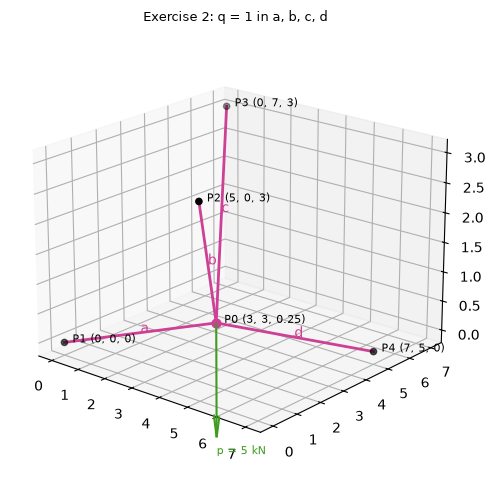

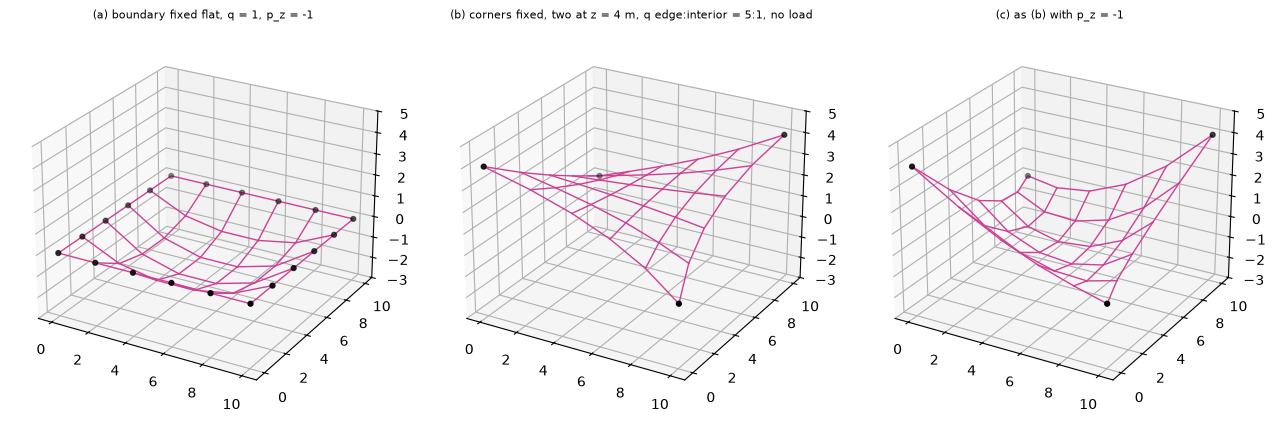

In [21]:
try:
    import matplotlib
    import matplotlib.pyplot as plt
    fig = plt.figure(figsize=(6, 5))
    ax = fig.add_subplot(projection="3d")
    for k in range(4):
        ax.plot(*zip(P0, P_fixed[k]), color="#ce4095", lw=2)
        ax.text(*P_fixed[k], f"  P{k + 1} ({P_fixed[k][0]:g}, {P_fixed[k][1]:g}, {P_fixed[k][2]:g})", fontsize=8)
        ax.text(*(P0 + P_fixed[k]) / 2, bars[k], fontsize=10, color="#ce4095")
    ax.scatter(*P_fixed.T, color="k", s=20); ax.scatter(*P0, color="#ce4095", s=40)
    ax.text(*P0, f"  P0 ({P0[0]:g}, {P0[1]:g}, {P0[2]:g})", fontsize=8)
    ax.quiver(*P0, 0, 0, -2.0, color="#3f9c20", arrow_length_ratio=0.2)
    ax.text(P0[0], P0[1], P0[2] - 2.3, "p = 5 kN", color="#3f9c20", fontsize=8)
    ax.set_title("Exercise 2: q = 1 in a, b, c, d", fontsize=9); ax.view_init(elev=20, azim=-50)
    fig.tight_layout(); plt.show()
    fig = plt.figure(figsize=(13, 4.2))
    for a_, (name, xyz, fixed, qq, pz) in enumerate(cases):
        ax = fig.add_subplot(1, 3, a_ + 1, projection="3d")
        for k1, k2 in grid_bars:
            ax.plot(*zip(xyz[k1], xyz[k2]), color="#ce4095", lw=1)
        ax.scatter(*xyz[fixed].T, color="k", s=12)
        ax.set_title(name, fontsize=8); ax.set_zlim(-3, 5); ax.view_init(elev=25, azim=-60)
    fig.tight_layout(); plt.show()
except ImportError:
    print("matplotlib not installed: no pictures")


## § 6.5 Materialization

**Equations (6.34)–(6.37)** — the shape is independent of the material. Afterwards, for a chosen axial stiffness $EA$, the cutting length
of every bar follows from Hooke's law; all matrices are diagonal, so per bar

$$
\mathbf l _ 0 = (\mathbf I + (\mathbf{EA})^{-1} \mathbf Q \mathbf L)^{-1} \mathbf l \qquad \Longrightarrow \qquad
l _ {0,k} = \frac{l_k}{1 + q_k l_k / EA_k}, \qquad l _ {0,a} = \frac{4.250}{1 + 4.250 / 500} = 4.214 \text{ m}
$$

Each bar is cut about 1 % short; stretched into place it carries exactly $F = q l$. (The printed "$l_0 \lt 1$" on p. 66 means $l_0 \lt l$.)

*Cell F.1 — 6.5 Materialization — cutting lengths for a chosen stiffness, (6.34)–(6.37)*


In [22]:
EA = np.diag([500.0, 500.0, 500.0, 500.0])           # kN, one value per bar
I = np.eye(4)
l0 = np.linalg.solve(I + np.linalg.inv(EA) @ Q @ L, l)   # (6.37): l0 = (I + EA^-1 Q L)^-1 l
e = l - l0                                           # (6.34): elastic elongation
print("stressed lengths l =", l)
print("cutting lengths l0 =", l0, " (each bar cut about 1 % short)")
print("elongations e = l - l0 =", e, "  check (6.34) L0 EA^-1 f =", np.diag(l0) @ np.linalg.inv(EA) @ F)
print("Hooke (6.1): EA/l0 * e =", np.diag(EA) / l0 * e, " = F =", F)


stressed lengths l = [4.25   4.5346 5.7064 4.4791]
cutting lengths l0 = [4.2142 4.4938 5.642  4.4393]  (each bar cut about 1 % short)
elongations e = l - l0 = [0.0358 0.0408 0.0644 0.0398]   check (6.34) L0 EA^-1 f = [0.0358 0.0408 0.0644 0.0398]
Hooke (6.1): EA/l0 * e = [4.25   4.5346 5.7064 4.4791]  = F = [4.25   4.5346 5.7064 4.4791]


## Exercises (pp. 68–69), answered above

1. Forces of 1 kN with a 5 kN load: no equilibrium exists (§ 6.2.3, third cell).
2. $q = 1$: $P_0 = (3, 3, 0.25)$, forces $4.25, 4.53, 5.71, 4.48$ kN; $q = 2$ in $b, d$: $P_0 = (4, 2.83, 0.67)$ (§ 6.2.3).
3. Branch-node matrix of Fig. 6.12: $60 \times 36$ (§ 6.4.4, first cell).
4. Shaping a shell: raise the corners, change the edge-to-interior ratio of $\mathbf q$, add $\mathbf p _ z$ (§ 6.4.4, third cell).
